# Spike-fade backtest on Yahoo hourly bars

**Goal.** Trade the regular-hours spike fade from notebook 05b.

**Method.** Short the close of an RTH hour whose return exceeded 2 trailing standard deviations. The next bar has to be exactly one hour later. Exit rules, judged only from that next hourly bar: 20-point stop, 15-point target, otherwise the next close. If the bar touches both stop and target, assume the stop filled. Two MNQ contracts, $2 per point, $1.50 commission per contract round trip, 1 point of slippage, $1,000 daily loss limit. The simulator is `src.simulate.simulate_hourly_bar`.

**Result.** 232 trades from 2024-07-12 to 2026-11-25, win rate 19.4%, average -14.2 points, total -$13,884, profit factor 0.15. The trailing-drawdown line was crossed on 2024-10-25. The next cell shows why: 146 of 232 next hours touched both the stop and the target, so the fill order is not identified at hourly resolution. A time exit at the next close, on the same trades, was +13.2 points per trade and about +$11,524. That number is still inside the window where the pattern was found.


In [ ]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


Trades:         232  (2024-07-12 to 2026-11-25)
Win rate:       19.4%
Avg trade:      $-59.84   (-14.2 pts after slippage)
Total P&L:      $-13,884
Profit factor:  0.15
Max drawdown:   $-13,884
Outcomes:       {'stop': 187, 'target': 45}
Trailing DD breached: YES on 2024-10-25

By year:
  2024:  51 trades | win 22% | P&L $-2,897
  2025:  83 trades | win 18% | P&L $-5,121
  2026:  98 trades | win 19% | P&L $-5,866


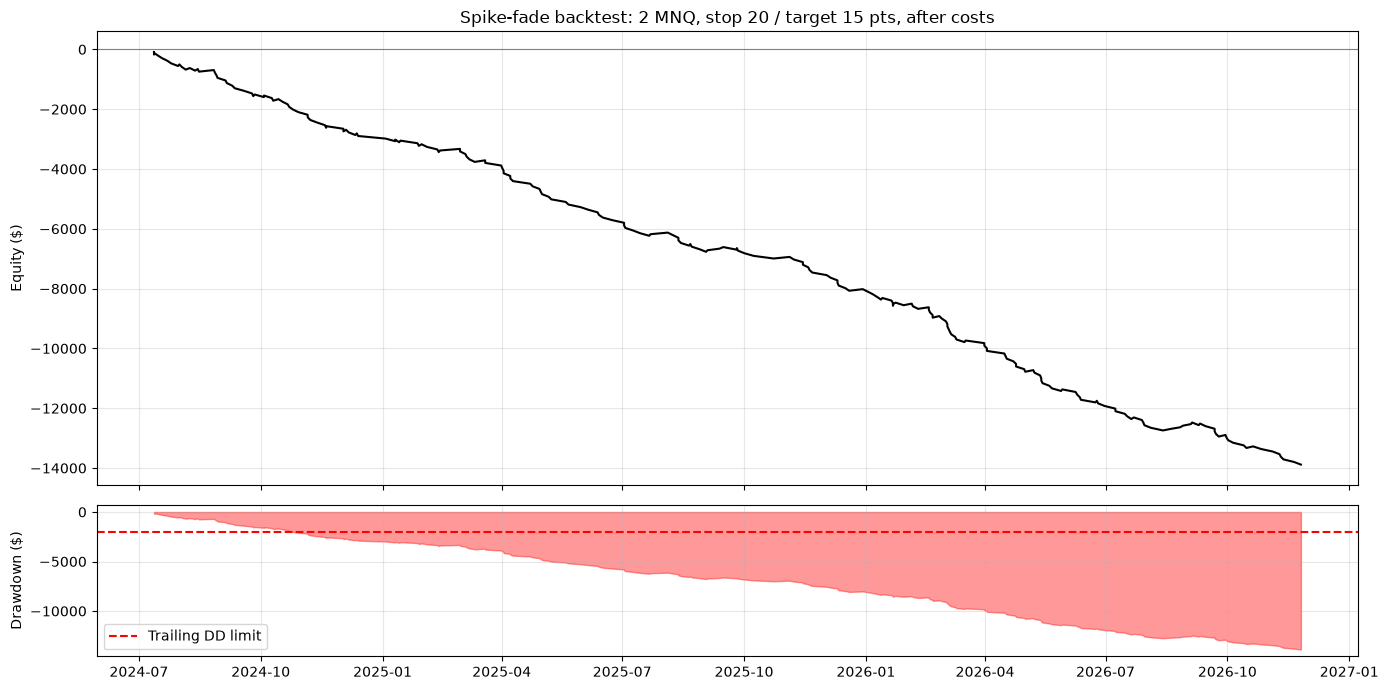

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.signals import return_zscore_series
from src.simulate import simulate_hourly_bar
from src.performance import equity_curve

z_cut = 2.0
vol_bars = 100
stop_pts = 20
target_pts = 15
contracts = 2
point_value = 2.0
commission_rt = 1.50
slippage_pts = 1.0
daily_loss_limit = 1000
trailing_dd = 2000

nq = yf.download("NQ=F", period="730d", interval="1h", multi_level_index=False, progress=False).dropna()
nq.index = nq.index.tz_convert("America/New_York")
z = return_zscore_series(nq["Close"], vol_bars)["z"]
t = simulate_hourly_bar(
    nq, z,
    z_cut=z_cut, stop_pts=stop_pts, target_pts=target_pts,
    contracts=contracts, point_value=point_value, commission_rt=commission_rt,
    slippage_pts=slippage_pts, daily_loss_limit=daily_loss_limit, vol_warmup=vol_bars,
)
t = equity_curve(t)
breach = t[t["drawdown"] <= -trailing_dd]
wins = t[t.pnl > 0]
losses = t[t.pnl <= 0]
pf = wins.pnl.sum() / abs(losses.pnl.sum()) if len(losses) else float("inf")

print(f"Trades:         {len(t)}  ({t.time.iloc[0].date()} to {t.time.iloc[-1].date()})")
print(f"Win rate:       {len(wins) / len(t):.1%}")
print(f"Avg trade:      ${t.pnl.mean():+.2f}   ({t.pts.mean():+.1f} pts after slippage)")
print(f"Total P&L:      ${t.pnl.sum():+,.0f}")
print(f"Profit factor:  {pf:.2f}")
print(f"Max drawdown:   ${t.drawdown.min():,.0f}")
print(f"Outcomes:       {t.outcome.value_counts().to_dict()}")
print("Trailing DD breached:", "YES on " + str(breach.time.iloc[0].date()) if len(breach) else "No")
print("\nBy year:")
for yr, g in t.groupby(t.time.dt.year):
    print(f"  {yr}: {len(g):3} trades | win {(g.pnl > 0).mean():.0%} | P&L ${g.pnl.sum():+,.0f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(t.time, t.equity, color="black")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set_title(f"Spike-fade backtest: {contracts} MNQ, stop {stop_pts} / target {target_pts} pts, after costs")
ax1.set_ylabel("Equity ($)")
ax1.grid(True, alpha=0.3)
ax2.fill_between(t.time, t.drawdown, 0, color="red", alpha=0.4)
ax2.axhline(-trailing_dd, color="red", linestyle="--", label="Trailing DD limit")
ax2.set_ylabel("Drawdown ($)")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(ROOT / "results" / "equity_yahoo_hourly.png", dpi=140)
plt.show()


In [2]:
both, ranges, raw = 0, [], []
for _, row in t.iterrows():
    i = nq.index.get_loc(row.time)
    entry = nq["Close"].iloc[i]
    nxt = nq.iloc[i + 1]
    ranges.append(nxt["High"] - nxt["Low"])
    if nxt["High"] >= entry + stop_pts and nxt["Low"] <= entry - target_pts:
        both += 1
    raw.append(entry - nxt["Close"] - slippage_pts)   # no stop/target, just exit at next close

raw = np.array(raw)
print(f"Next hour touched BOTH stop and target: {both} of {len(t)} trades")
print(f"Avg next-hour range after a spike:     {np.mean(ranges):.0f} pts")
print(f"\nTime exit only (no stop/target):")
print(f"  avg {raw.mean():+.1f} pts | win {np.mean(raw > 0):.0%} | "
      f"total ${raw.sum() * point_value * contracts - commission_rt * contracts * len(raw):+,.0f}")


Next hour touched BOTH stop and target: 146 of 232 trades
Avg next-hour range after a spike:     143 pts

Time exit only (no stop/target):
  avg +13.2 pts | win 55% | total $+11,524
